<a href="https://colab.research.google.com/github/juliaf22/TFM-HERMION3/blob/main/walk_the_path_spectral.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Intro to Computational Cytometry · IGTP–IJC Flow Cytometry Course · 29 Oct 2026
**Walk the path: what is in the blood of 4 donors?**

We have **spectral flow cytometry data (Cytek Aurora)** from PBMC of **4 donors**, stained with a 30-colour panel.
Nobody has gated them. **Can we find out what is in there without drawing a single gate?**

**1 Read → 2 Look → 3 QC → 4 Transform → 5 Cluster → 6 Visualise**

**We start from unmixed FCS files**: the cytometer software has already done the unmixing.

Cells marked **✋ Your turn** are for you to try. Cells marked **⏩ Optional** are for later.

*Example data: open-source files from the R package [Luciernaga](https://github.com/DavidRach/Luciernaga) (D. Rach).*

## ⏱ Run this cell NOW (≈10 min), while the previous talk is going on
Make sure the runtime is **R** (*Runtime → Change runtime type → R*).

In [ ]:
if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")
if (!requireNamespace("ggplot2", quietly = TRUE)) install.packages("ggplot2")
BiocManager::install(c("flowCore", "FlowSOM", "PeacoQC", "uwot"), ask = FALSE, update = FALSE)

pkgs <- c("flowCore", "FlowSOM", "PeacoQC", "uwot", "ggplot2")
ok <- sapply(pkgs, requireNamespace, quietly = TRUE)
if (all(ok)) cat("Setup done ✅\n") else cat("Missing:", pkgs[!ok], "❌\n")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'flowCore', 'FlowSOM', 'PeacoQC', 'uwot'

also installing the dependencies ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘filelock’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘dir.expiry’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘XVector’, ‘biocmake’, ‘corrplot’, ‘car’, ‘rjson’, ‘iterators’, ‘MatrixGenerics’, ‘S4Arrays’, ‘SparseArray’, ‘Rhdf5lib’, ‘ALL’, ‘tweenr’, ‘polyclip’, ‘ggrepel’, ‘ggsci’, ‘cowplot’, ‘ggsignif’, ‘polynom’, ‘rstatix’, ‘GlobalOptions’, ‘shape’, ‘colorspace’, ‘Getopt

---
# 1 · Read
An FCS file is a **table: one row per cell (event), one column per parameter** (scatter, fluorescence, time...).
Our files are **already unmixed** by the instrument software (one column per fluorochrome, no spillover matrix). We download the 4 donors from GitHub.

In [ ]:
suppressPackageStartupMessages({
  library(ggplot2); library(flowCore); library(PeacoQC); library(FlowSOM); library(uwot)
})
options(repr.plot.width = 11, repr.plot.height = 5.5, repr.plot.res = 120)
theme_set(theme_minimal(base_size = 16) +
          theme(panel.grid.minor = element_blank(),
                plot.title = element_text(face = "bold"),
                strip.text = element_text(face = "bold")))

base <- "https://raw.githubusercontent.com/DavidRach/Luciernaga/main/inst/extdata/"
get_file <- function(f) {
  dest <- file.path(tempdir(), f)
  if (!file.exists(dest)) download.file(paste0(base, URLencode(f)), dest, quiet = TRUE, mode = "wb")
  dest
}

samples <- c(INF071 = "INF071_Ctrl_Tetramer.fcs",
             INF149 = "INF149_Ctrl_Tetramer.fcs",
             INF179 = "INF179_Ctrl_Tetramer.fcs",
             ND050  = "ND050_15_Ctrl_Tetramer.fcs")

ffs <- lapply(samples, function(f) read.FCS(get_file(f), truncate_max_range = FALSE))
ff  <- ffs[[1]]

In [ ]:
ff

flowFrame object 'INF071_Ctrl_Tetramer_Unmixed.fcs'
with 2000 cells and 40 observables:
               name      desc     range  minRange  maxRange
$P1            Time        NA    952930         0    952929
$P2           SSC-W        NA   4194304         0   4194303
$P3           SSC-H        NA   4194304         0   4194303
$P4           SSC-A        NA   4194304         0   4194303
$P5           FSC-W        NA   4194304         0   4194303
...             ...       ...       ...       ...       ...
$P36     APC-R700-A    CD107a   4194304      -111   4194303
$P37   Zombie NIR-A Viability   4194304      -111   4194303
$P38 APC-Fire 750-A      CD27   4194304      -111   4194303
$P39 APC-Fire 810-A      CD38   4194304      -111   4194303
$P40           AF-A        NA   4194304      -111   4194303
442 keywords are stored in the 'description' slot

### ✋ Your turn
How many events and parameters does each file have?

<details>
<summary><b>Show answer</b></summary>

2,000 events and 40 parameters per file, and 4 files.

</details>

In [ ]:
cat("Events per file:", nrow(ff), "| Parameters:", ncol(ff), "| Files:", length(ffs), "\n")

Events per file: 2000 | Parameters: 40 | Files: 4 


# 2 · Look
Each parameter has a **channel** (fluorochrome) and a **marker** (the target). `AF-A` is the autofluorescence channel extracted during unmixing: it is not a marker.

In [ ]:
p  <- pData(parameters(ff))
p

,name,desc,range,minRange,maxRange
,<I<chr>>,<I<chr>>,<dbl>,<dbl>,<dbl>
$P1,Time,NA,952930,0,952929
$P2,SSC-W,NA,4194304,0,4194303
$P3,SSC-H,NA,4194304,0,4194303
$P4,SSC-A,NA,4194304,0,4194303
$P5,FSC-W,NA,4194304,0,4194303
$P6,FSC-H,NA,4194304,0,4194303
$P7,FSC-A,NA,4194304,0,4194303
$P8,SSC-B-W,NA,4194304,0,4194303
$P9,SSC-B-H,NA,4194304,0,4194303


### ✋ Your turn
Which parameters are **not** markers? (Look at the channel list of `ff`: scatter, time and one fluorescence channel have no marker name.)

<details>
<summary><b>Show answer</b></summary>

**Time**, the **scatter** channels (FSC and SSC, in area, height and width) and **AF-A**, the extracted autofluorescence channel. They are not markers, so we do not use them for clustering.

</details>

In [ ]:
mk <- setNames(as.character(p$desc), p$name)
mk <- mk[!is.na(mk) & mk != ""]            # channel -> marker dictionary
data.frame(channel = names(mk), marker = unname(mk), row.names = NULL)

channel,marker
<chr>,<chr>
BUV395-A,CD62L
BUV496-A,CD8
BUV563-A,CD69
BUV615-A,CCR4
BUV661-A,VD2
BUV737-A,CXCR3
BUV805-A,CD4
BV421-A,CD127
Pacific Blue-A,Lineage-


---
# 3 · QC: remove what is not a real cell
- **Margin events:** cells at the detector's limit (saturated); their real value is unknown. We check them on **scatter**.
- **Doublets:** two cells read as one (area FSC-A too large for their height FSC-H).

In [ ]:
qc_channels <- c("FSC-A", "SSC-A")   # margins only on scatter: unmixed fluorescence is legitimately negative

ffs_qc <- lapply(ffs, function(f) RemoveDoublets(RemoveMargins(f, channels = qc_channels)))

counts <- data.frame(sample   = names(ffs),
                     start    = sapply(ffs, nrow),
                     after_QC = sapply(ffs_qc, nrow))
counts$removed_pct <- round(100 * (1 - counts$after_QC / counts$start), 1)
counts

Warning message in RemoveMargins(f, channels = qc_channels):
“More than 10.95 % is considered as a margin event in file INF149_Ctrl_Tetramer.fcs . This should be verified.”


,sample,start,after_QC,removed_pct
,<chr>,<int>,<int>,<dbl>
INF071,INF071,2000,1637,18.1
INF149,INF149,2000,1660,17.0
INF179,INF179,2000,1691,15.4
ND050,ND050,2000,1660,17.0


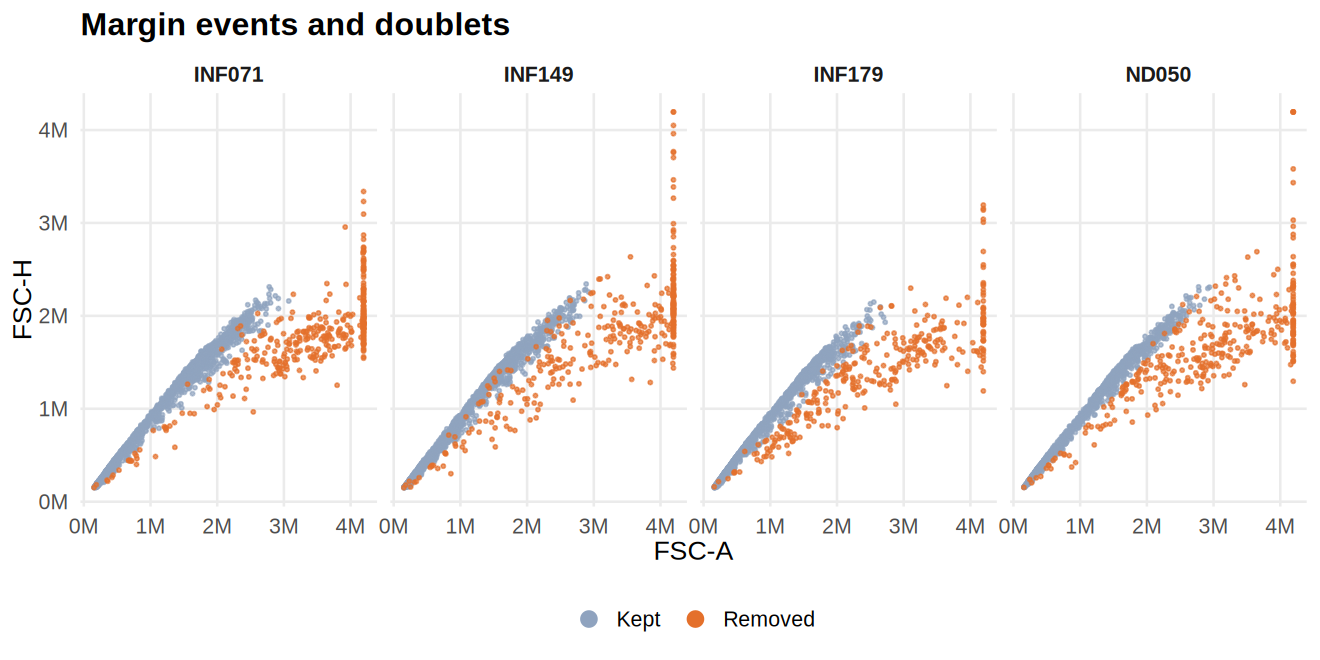

In [ ]:
key <- function(f) paste(exprs(f)[, "Time"], exprs(f)[, "FSC-A"])
qc_df <- do.call(rbind, lapply(names(ffs), function(s) {
  m <- exprs(ffs[[s]])
  data.frame(sample = s, FSC_A = m[, "FSC-A"], FSC_H = m[, "FSC-H"],
             status = ifelse(key(ffs[[s]]) %in% key(ffs_qc[[s]]), "Kept", "Removed"))
}))
qc_df$status <- factor(qc_df$status, levels = c("Kept", "Removed"))
qc_df <- qc_df[order(qc_df$status), ]        # removed events drawn on top

ggplot(qc_df, aes(FSC_A, FSC_H, color = status)) +
  geom_point(size = 0.7, alpha = 0.7) +
  facet_wrap(~sample, nrow = 1) +
  scale_color_manual(values = c(Kept = "#8FA3BF", Removed = "#E4702B"), name = NULL) +
  scale_x_continuous(labels = scales::label_number(scale = 1e-6, suffix = "M")) +
  scale_y_continuous(labels = scales::label_number(scale = 1e-6, suffix = "M")) +
  guides(color = guide_legend(override.aes = list(size = 4, alpha = 1))) +
  labs(x = "FSC-A", y = "FSC-H", title = "Margin events and doublets") +
  theme(legend.position = "bottom")

### ✋ Your turn
- Where are the doublets in these plots?
- Which donor lost the most events? Is that a problem?

<details>
<summary><b>Show answer</b></summary>

- **Doublets:** the orange points **below the diagonal** (FSC-A too large for their FSC-H).
- **Margin events:** the orange column at the **right edge** (FSC-A at the detector maximum).
- **Most events lost:** INF071 (18.1%), then INF149 and ND050 (17.0%), and INF179 (15.4%). The percentages are similar, so it is **not a problem**. A donor losing much more than the others would deserve a look.

</details>

> 🔑 In a real analysis you would also exclude **dead cells** (viability dye) and, on full-size files, check **flow stability over time** (*PeacoQC*). Our files are subsampled to 2,000 events, too few for that.

---
# 4 · Transform
Fluorescence spans several orders of magnitude with negatives around zero. We use **arcsinh**: `asinh(x / cofactor)`. It behaves like `x / cofactor` near zero (linear) and like `log(2x / cofactor)` for large values (logarithmic).
The **cofactor** is a choice. Aurora values are on a large scale: a few thousand is a common starting point.

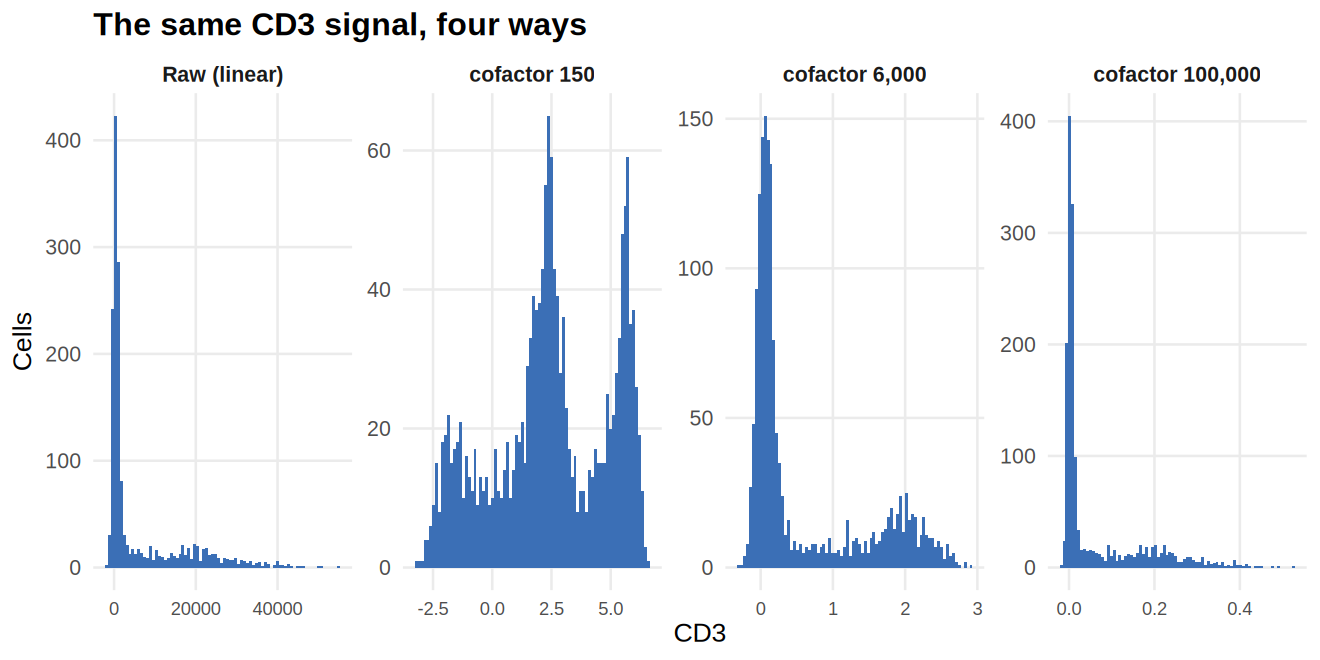

In [ ]:
x <- exprs(ffs_qc[[1]])[, names(mk)[mk == "CD3"]]

dd <- rbind(data.frame(panel = "Raw (linear)", value = x),
            do.call(rbind, lapply(c(150, 6000, 100000), function(cf)
              data.frame(panel = paste("cofactor", format(cf, big.mark = ",", scientific = FALSE)), value = asinh(x / cf)))))
dd$panel <- factor(dd$panel, levels = unique(dd$panel))

ggplot(dd, aes(value)) +
  geom_histogram(bins = 80, fill = "#3B6FB6") +
  facet_wrap(~panel, nrow = 1, scales = "free") +
  labs(x = "CD3", y = "Cells", title = "The same CD3 signal, four ways") +
  theme(axis.text.x = element_text(size = 11))

### ✋ Your turn
- With which cofactor do you clearly see **negative and positive** CD3 populations?
- What happens with a cofactor **too small**? And **too large**?
- Change `"CD3"` to `"CD4"` or `"CD8"`. Is the best cofactor the same?

<details>
<summary><b>Show answer</b></summary>

- **Best cofactor: 6,000.** There is a big negative peak near 0 and a clearly separated positive population.
- **Too small (150):** noise stretches the negatives and the populations spread and split into several peaks.
- **Too large (100,000):** everything collapses near 0 and the positive population is no longer visible.
- **With CD4 or CD8:** the best cofactor **can change**, because the background noise is different in each channel. That is why in spectral data it is often optimised per channel.

</details>

We apply **cofactor 6000** to every marker of every donor and build one table (cells × markers).
We leave out the **viability dye** and the two **tetramers** (almost no cells are tetramer-positive in these files).

In [ ]:
cf    <- 6000
ffs_t <- lapply(ffs_qc, function(f)
  transform(f, transformList(names(mk), arcsinhTransform(a = 0, b = 1 / cf, c = 0))))

use              <- mk[!(mk %in% c("Viability", "hMR1-5-OP-RU", "hCD1d-PBS-57"))]
cluster_channels <- names(use)
markers          <- unname(use)

dat <- do.call(rbind, lapply(names(ffs_t), function(s) {
  m <- exprs(ffs_t[[s]])[, cluster_channels]
  colnames(m) <- markers
  data.frame(m, sample = s, check.names = FALSE)
}))
dat_raw <- do.call(rbind, lapply(ffs_qc, function(f) {
  m <- exprs(f)[, cluster_channels]; colnames(m) <- markers; as.data.frame(m)
}))   # untransformed, for the cofactor test below

cat("Cells:", nrow(dat), "| Markers used:", length(markers), "\n")
table(dat$sample)

Cells: 6648 | Markers used: 26 



INF071 INF149 INF179  ND050 
  1637   1660   1691   1660 

## Does the cofactor change the *result*, not just the picture?
The honest test is not how a histogram looks: it is whether the **downstream analysis** finds the same thing.
We run the whole clustering pipeline three times, changing only the cofactor, and ask how well each run recovers a **rare population** defined on the raw data (the brightest 1.5% of VD2, about 100 cells).

In [ ]:
gd_ref <- dat_raw$VD2 > quantile(dat_raw$VD2, 0.985)   # reference set, defined before any scaling

score <- function(cf) {
  d  <- as.data.frame(asinh(as.matrix(dat_raw) / cf))
  m  <- GetMetaclusters(FlowSOM(flowFrame(as.matrix(d)), colsToUse = markers,
                                xdim = 7, ydim = 7, nClus = 12, seed = 42))
  j  <- sapply(levels(m), function(k) sum(m == k & gd_ref) / sum(m == k | gd_ref))
  k  <- names(which.max(j))
  data.frame(cofactor = cf, jaccard = round(max(j), 2),
             purity = round(100 * sum(m == k & gd_ref) / sum(m == k)),
             recall = round(100 * sum(m == k & gd_ref) / sum(gd_ref)))
}

do.call(rbind, lapply(c(150, 6000, 100000), score))

cofactor,jaccard,purity,recall
<dbl>,<dbl>,<dbl>,<dbl>
150,0.49,72,60
6000,0.74,89,81
100000,0.03,3,86


### ✋ Your turn
Which cofactor recovers the rare population best? What happens at 100,000?
<details>
<summary><b>Show answer</b></summary>

In our test run: **cofactor 150** → Jaccard 0.49 (purity 72%, recall 60%); **6,000** → Jaccard 0.74 (purity 89%, recall 81%); **100,000** → Jaccard 0.03 (purity 3%).

At 100,000 the rare cells are still *found*, but they are swallowed into a large cluster that is 97% other cells — the population exists in the data and not in the result. The cofactor is not cosmetic: it decides what the clustering can resolve.

</details>

---
# 5 · Cluster with FlowSOM
FlowSOM groups cells that look alike across **all markers**: first a **self-organising map** of 7×7 = 49 nodes, then a **consensus hierarchical clustering** of the nodes into `nClus` final clusters.

In [ ]:
if (nrow(dat) < 500) stop("Only ", nrow(dat), " cells left after QC: check the QC table in section 4")

ff_all <- flowFrame(as.matrix(dat[, markers]))

set.seed(42)
fsom <- FlowSOM(ff_all, colsToUse = markers, xdim = 7, ydim = 7, nClus = 12, seed = 42)
mc   <- GetMetaclusters(fsom)          # final cluster of every cell
table(mc)

mc
   1    2    3    4    5    6    7    8    9   10   11   12 
 227  455  891  232  232  536   91 1174  268  893 1013  636 

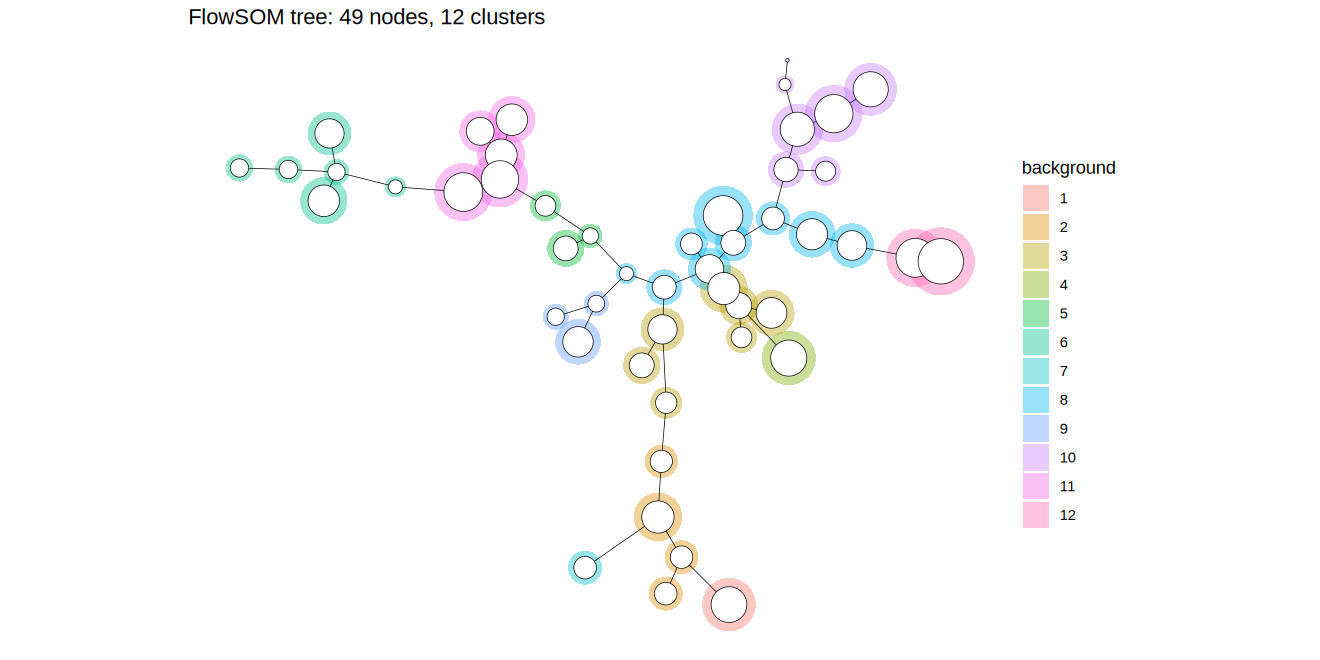

In [ ]:
PlotFlowSOM(fsom, backgroundValues = fsom$metaclustering) + labs(title = "FlowSOM tree: 49 nodes, 12 clusters")

## Name the clusters from their markers
A cluster has no name yet. We read its **median marker expression** and propose a label with a few simple rules (CD3 → T cells; CD4 / CD8 / Vδ2 → type; CD45RA and CD27 → naive-like; CD56 / CD16 / CD7 → NK-like; Lineage → B/monocyte-like).
**A label is a hypothesis, not a fact.**

In [ ]:
med <- aggregate(dat[, markers], by = list(cluster = mc), FUN = median)
rownames(med) <- med$cluster; med$cluster <- NULL

label_cluster <- function(m) {
  if (m["CD3"] >= 1.2) {
    type <- if (m["VD2"] >= 1.5) "Vδ2 γδ T" else if (m["CD4"] >= 1.5) "CD4 T" else if (m["CD8"] >= 1.5) "CD8 T" else "CD4-CD8- T"
    if (type != "Vδ2 γδ T")
      type <- paste(type, if (m["CD45RA"] >= 1.5 && m["CD27"] >= 1.5) "naive-like" else "memory-like")
    type
  } else if (m["CD3"] >= 0.8)                                     "CD3-dim / mixed"
  else if (m["CD56"] >= 1.0 || (m["CD16"] >= 1.0 && m["CD7"] >= 1.5)) "NK"
  else if (m["Lineage-"] >= 2)                                    "Lineage+ (B / monocyte-like)"
  else if (m["CD16"] >= 1.0)                                      "CD16+ myeloid-like"
  else if (m["CD7"] >= 2.5)                                       "CD7+ NK-like (CD56 low)"
  else if (m["CD45RA"] >= 1.5)                                    "CD45RA+ non-T (B-cell-like)"
  else                                                            "Other / low signal"
}

n_cells <- as.vector(table(mc))
labels  <- paste0("C", rownames(med), " · ", apply(med, 1, label_cluster), " (n=", n_cells, ")")
names(labels) <- rownames(med)
mc_named <- factor(labels[as.character(mc)], levels = labels)
labels

1 
                           "C1 · NK (n=227)" 
                                           2 
      "C2 · CD7+ NK-like (CD56 low) (n=455)" 
                                           3 
           "C3 · Other / low signal (n=891)" 
                                           4 
           "C4 · CD16+ myeloid-like (n=232)" 
                                           5 
            "C5 · CD4 T memory-like (n=232)" 
                                           6 
             "C6 · CD8 T naive-like (n=536)" 
                                           7 
                      "C7 · Vδ2 γδ T (n=91)" 
                                           8 
          "C8 · Other / low signal (n=1174)" 
                                           9 
            "C9 · CD4 T memory-like (n=268)" 
                                          10 
 "C10 · CD45RA+ non-T (B-cell-like) (n=893)" 
                                          11 
           "C11 · CD4 T naive-like (n=1013)" 
                                          12 
"C12 · Lineage+ (B / monocyte-like) (n=636)"

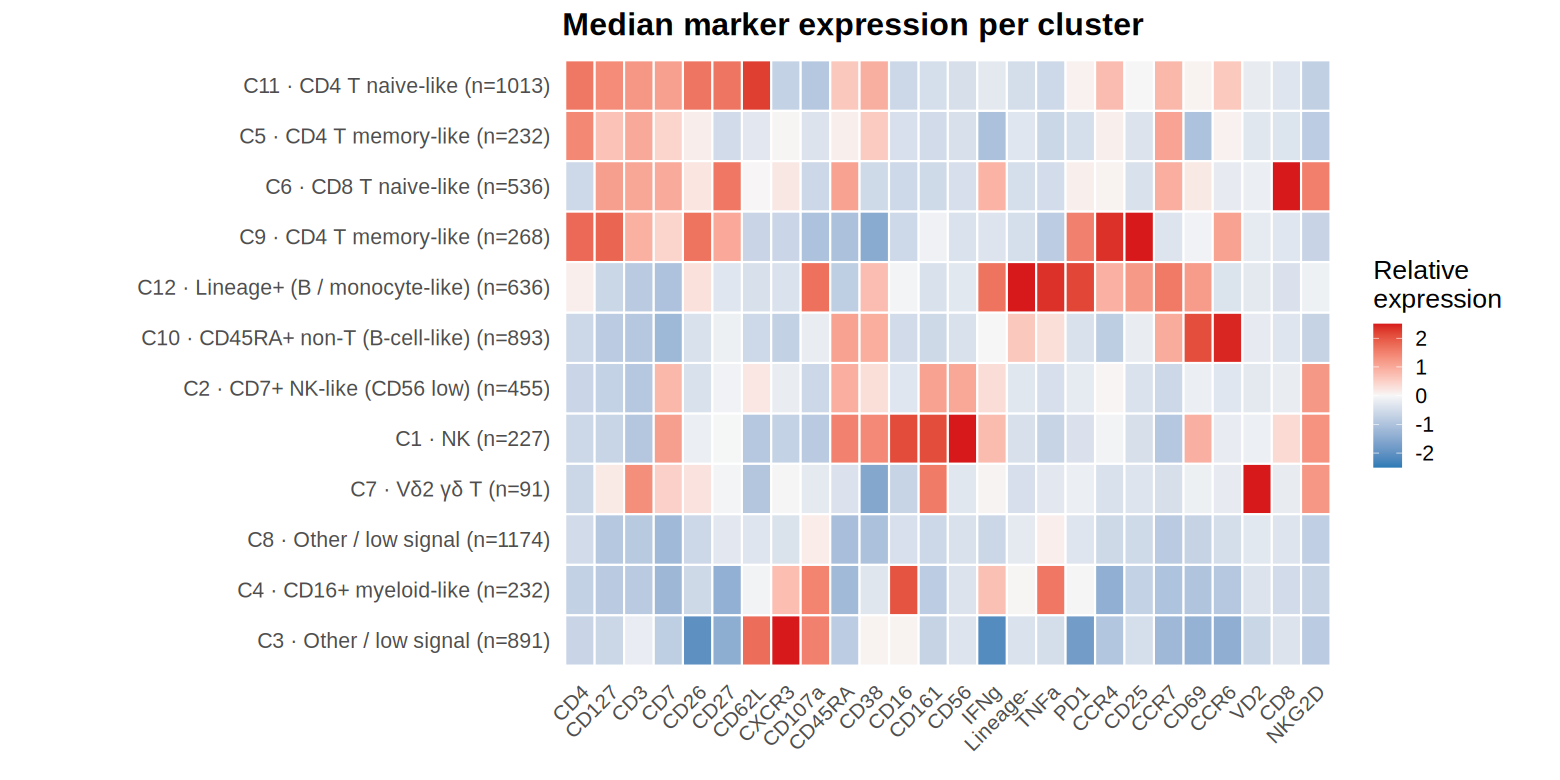

In [ ]:
options(repr.plot.width = 13, repr.plot.height = 6.5)

z  <- scale(med)                                   # z-score each marker across clusters
hm <- data.frame(cluster = rep(labels, ncol(z)),
                 marker  = rep(colnames(z), each = nrow(z)),
                 z       = as.vector(z))
hm$cluster <- factor(hm$cluster, levels = labels[hclust(dist(z))$order])
hm$marker  <- factor(hm$marker,  levels = colnames(z)[hclust(dist(t(z)))$order])

ggplot(hm, aes(marker, cluster, fill = z)) +
  geom_tile(color = "white", linewidth = 0.6) +
  scale_fill_gradient2(low = "#2C7BB6", mid = "#F7F7F7", high = "#D7191C", limits = c(-2.5, 2.5),
                       oob = scales::squish, name = "Relative\nexpression") +
  labs(x = NULL, y = NULL, title = "Median marker expression per cluster") +
  theme(panel.grid = element_blank(), axis.text.x = element_text(angle = 45, hjust = 1))

options(repr.plot.width = 11, repr.plot.height = 5.5)

### ✋ Your turn
- Do the labels make sense? Look for a cluster you would **not** have found by gating.
- Which clusters are small? One of them should be **Vδ2 γδ T cells**.
- Is **12** the right number of clusters? How would you decide?

<details>
<summary><b>Show answer</b></summary>

- **Do the names make sense?** The main ones do: CD4 T, CD8 T, NK, B / monocyte-like. Remember they are hypotheses, and some clusters stay as "Other / low signal".
- **A cluster you would not have found by simple gating:** **Vδ2 γδ T cells**. It is rare (about 1% of cells, 91 cells in our run) and only appears when you look at VD2 and CD3 together.
- **Is 12 the right number?** There is no single right number. Try several (6, 12, 24) and keep the one that separates populations with biological meaning. If two clusters look the same in the heatmap, merge them. It is usually safer to over-cluster and merge than to under-cluster.

</details>

---
# 6 · Visualise: UMAP
UMAP squeezes 26 dimensions into 2. It is a **picture** to look at the clusters, not a measurement.

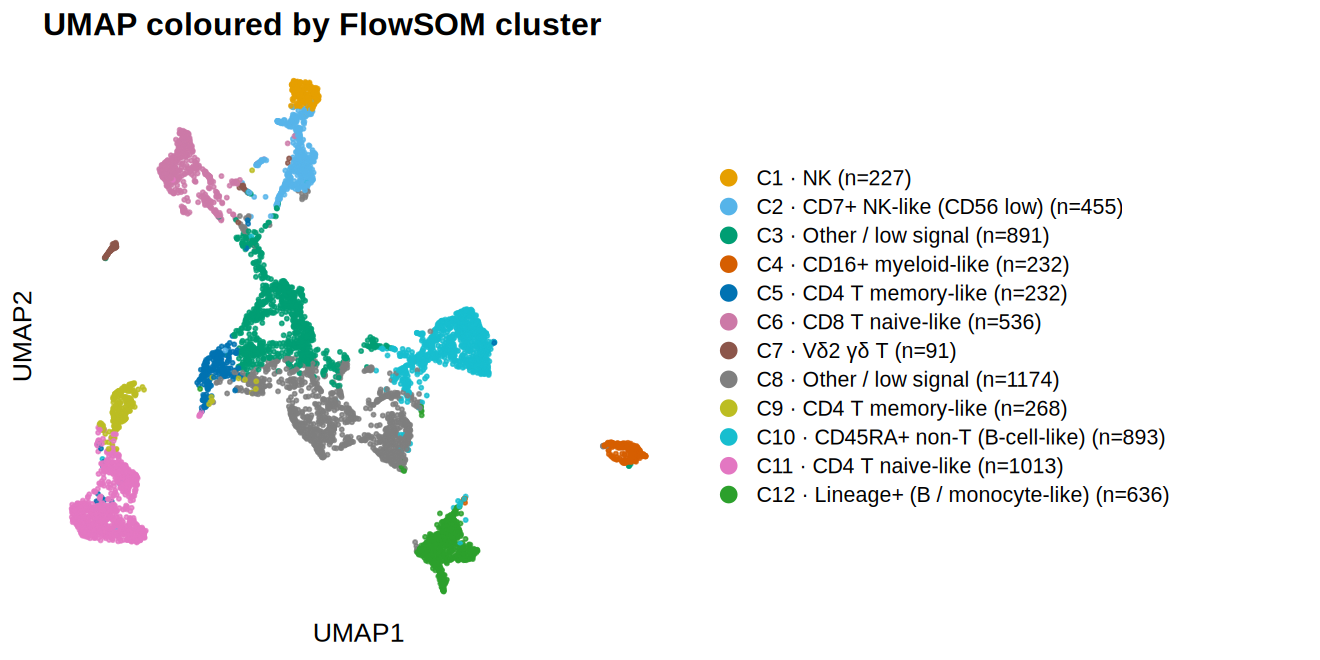

In [ ]:
set.seed(1)
um  <- umap(as.matrix(dat[, markers]), n_neighbors = 15, min_dist = 0.2)
viz <- data.frame(UMAP1 = um[, 1], UMAP2 = um[, 2], cluster = mc_named, sample = dat$sample)

pal12 <- c("#E69F00", "#56B4E9", "#009E73", "#D55E00", "#0072B2", "#CC79A7",
           "#8C564B", "#7F7F7F", "#BCBD22", "#17BECF", "#E377C2", "#2CA02C")
pal   <- setNames(pal12[seq_along(labels)], labels)

ggplot(viz, aes(UMAP1, UMAP2, color = cluster)) +
  geom_point(size = 0.7, alpha = 0.8) +
  scale_color_manual(values = pal, name = NULL) +
  guides(color = guide_legend(override.aes = list(size = 4, alpha = 1))) +
  labs(title = "UMAP coloured by FlowSOM cluster") +
  theme(panel.grid = element_blank(), axis.text = element_blank())

### Is the map telling the truth? Colour it by markers

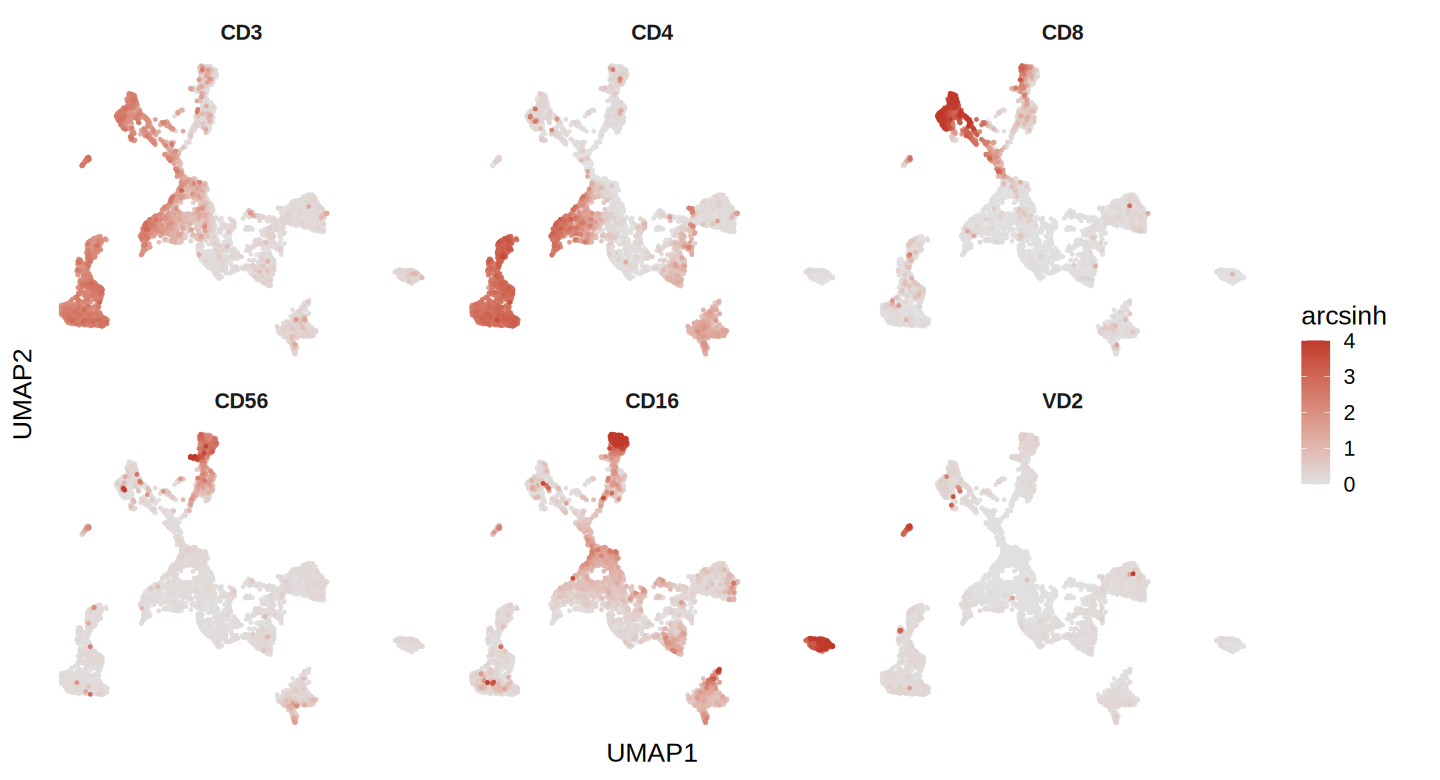

In [ ]:
show <- c("CD3", "CD4", "CD8", "CD56", "CD16", "VD2")
long <- do.call(rbind, lapply(show, function(g)
  data.frame(UMAP1 = viz$UMAP1, UMAP2 = viz$UMAP2, marker = g, value = dat[[g]])))
long$marker <- factor(long$marker, levels = show)
long <- long[order(long$value), ]                      # high values drawn on top

options(repr.plot.width = 12, repr.plot.height = 6.5)
ggplot(long, aes(UMAP1, UMAP2, color = value)) +
  geom_point(size = 0.4) +
  facet_wrap(~marker, nrow = 2) +
  scale_color_gradient(low = "grey88", high = "#C0392B", limits = c(0, 4), oob = scales::squish, name = "arcsinh") +
  theme(panel.grid = element_blank(), axis.text = element_blank())
options(repr.plot.width = 11, repr.plot.height = 5.5)

### Before you believe a cluster: look at the donors

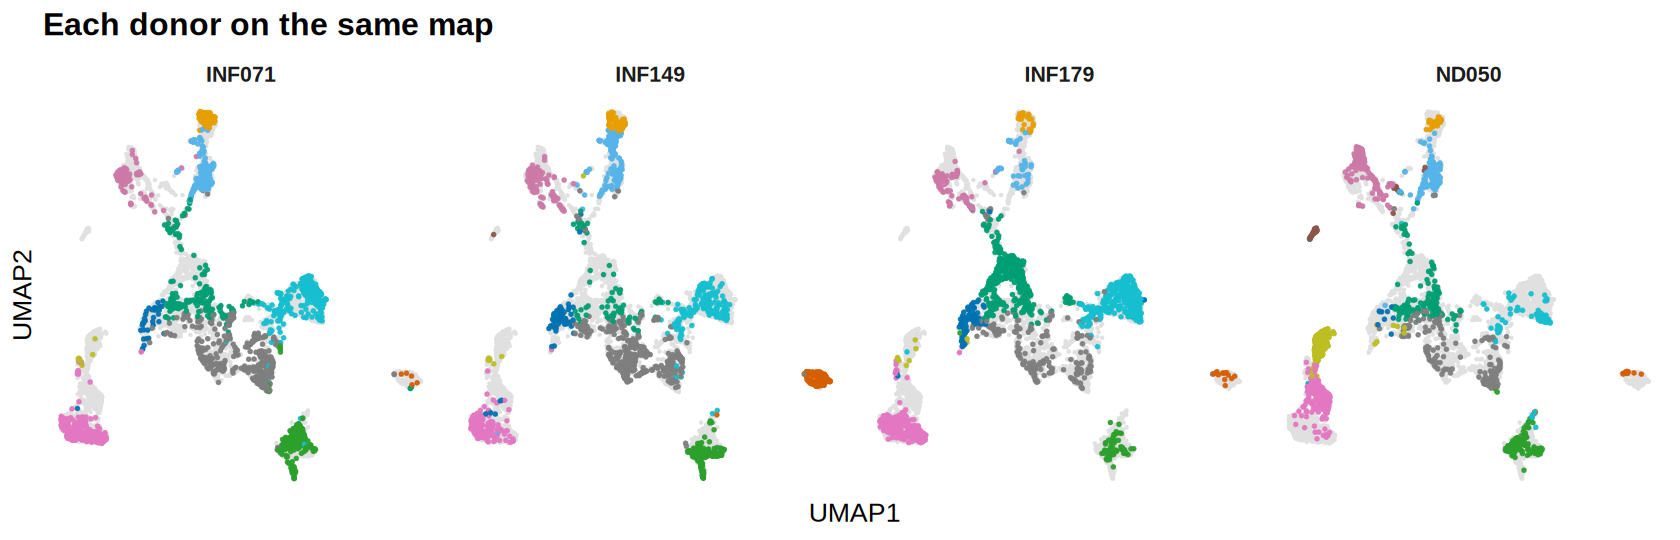

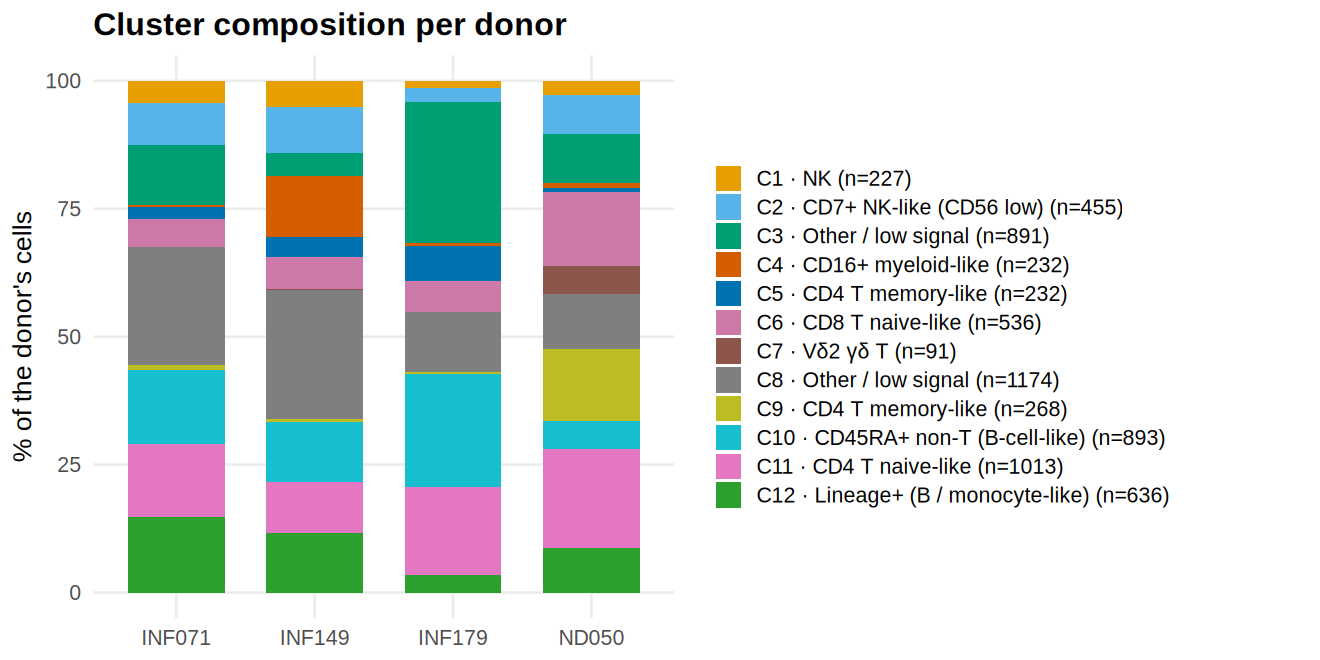

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 4.5)
ggplot(viz, aes(UMAP1, UMAP2)) +
  geom_point(data = viz[, c("UMAP1", "UMAP2")], color = "grey88", size = 0.3) +
  geom_point(aes(color = cluster), size = 0.6, alpha = 0.9) +
  facet_wrap(~sample, nrow = 1) +
  scale_color_manual(values = pal, name = NULL) +
  guides(color = "none") +
  labs(title = "Each donor on the same map") +
  theme(panel.grid = element_blank(), axis.text = element_blank())

options(repr.plot.width = 11, repr.plot.height = 5.5)
comp <- as.data.frame(prop.table(table(viz$sample, viz$cluster), 1) * 100)
ggplot(comp, aes(Var1, Freq, fill = Var2)) +
  geom_col(width = 0.7) +
  scale_fill_manual(values = pal, name = NULL) +
  labs(x = NULL, y = "% of the donor's cells", title = "Cluster composition per donor")

### ✋ Your turn
- Are all clusters present in **all 4 donors**?
- Look at the **Vδ2 γδ T** cluster. In which donor are the cells? Is that **biology** or a **batch effect**?
  (Hint: the file names tell you something: `INF...` and `ND...`. We cannot know from the files alone.)

<details>
<summary><b>Show answer</b></summary>

- **Are all clusters in all 4 donors?** The main lineages are. Exceptions: **Vδ2 γδ T** almost only in **ND050** (about 5% of its cells versus about 0%), and the **CD16+** cluster strongly enriched in **INF149** (about 12%).
- **Biology or batch?** It cannot be decided from these files alone.
  - For **biology:** donor-specific Vδ2 γδ expansions are plausible.
  - For **batch:** ND050 has a different name series (ND versus INF), which may mean another cohort or acquisition day, and its CD4 T region looks shifted on the UMAP.
  - To resolve it: metadata (date, instrument), a control sample in every batch, and more donors per batch.

</details>

> 🔑 A cluster that comes from a single donor is a **question**, not a result. You need metadata, controls and more donors.

### What we saw in our test run
*(Clusters can differ slightly between package versions, so check your own plots.)*
- Without any gating we recover the **main lineages**: CD4 T, CD8 T, NK, B / monocyte-like cells.
- A **rare Vδ2 γδ T cluster (~1% of cells)** forms its own island, and it comes **almost entirely from one donor (ND050)**.
- **INF149** is rich in a CD16+ cluster; **ND050** also looks shifted within the CD4 T region.
- With 4 donors we **cannot tell biology from batch**. That is the honest conclusion, and the next experiment.

### ⏩ Optional: how many clusters? Try it

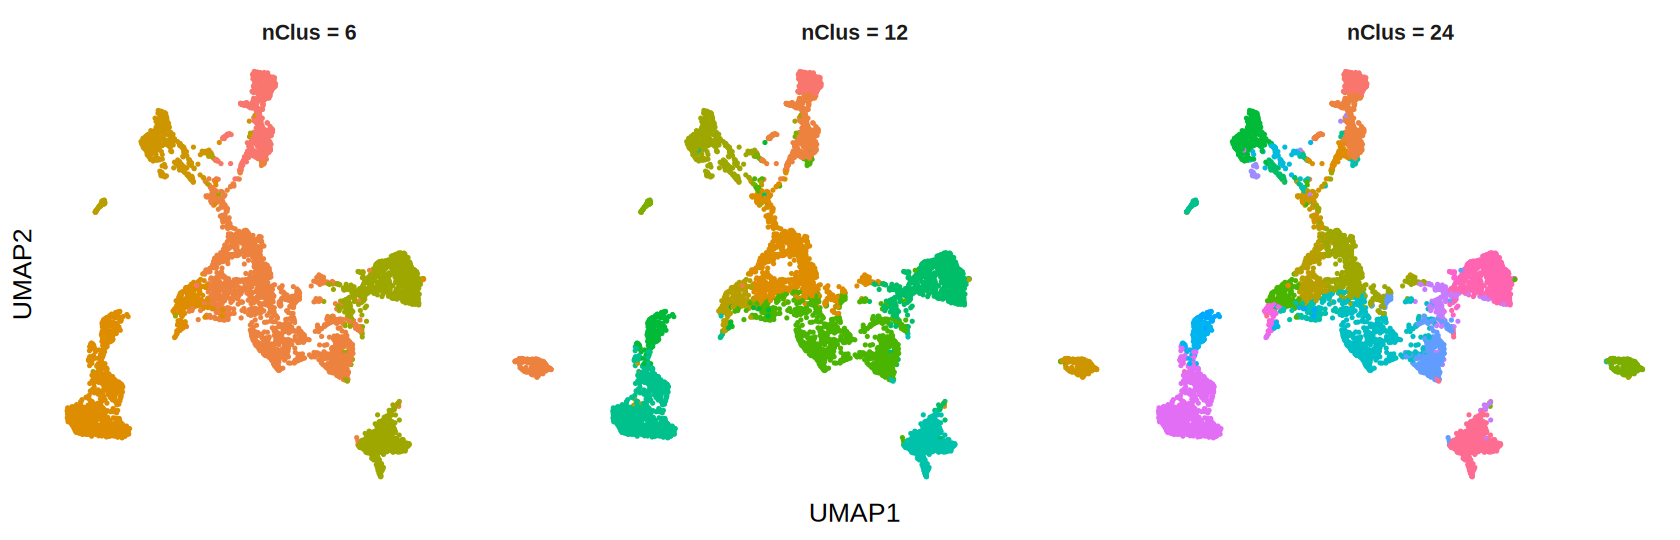

In [ ]:
tryn <- do.call(rbind, lapply(c(6, 12, 24), function(n) {
  f <- FlowSOM(ff_all, colsToUse = markers, xdim = 7, ydim = 7, nClus = n, seed = 42)
  data.frame(UMAP1 = viz$UMAP1, UMAP2 = viz$UMAP2, nClus = paste("nClus =", n),
             cl = factor(GetMetaclusters(f)))
}))
tryn$nClus <- factor(tryn$nClus, levels = paste("nClus =", c(6, 12, 24)))

options(repr.plot.width = 14, repr.plot.height = 4.5)
ggplot(tryn, aes(UMAP1, UMAP2, color = cl)) +
  geom_point(size = 0.5) +
  facet_wrap(~nClus, nrow = 1) +
  guides(color = "none") +
  theme(panel.grid = element_blank(), axis.text = element_blank())
options(repr.plot.width = 11, repr.plot.height = 5.5)

### ✋ Your turn
What changes with 6, 12 or 24 clusters? Which populations merge, which split?
<details>
<summary><b>Show answer</b></summary>

With **6** clusters the large central region becomes a single cluster and populations that are close merge (for example CD4 T naive and memory). With **24** the same islands are cut into more pieces: some splits may be real sub-states, others are just noise. **12** is a reasonable middle ground here, but the choice is yours: justify it with the heatmap.

</details>

---
## Is the clustering stable? FlowSOM starts from a random initialisation
Re-run it with another seed and you get another partition. **How much another?** The adjusted Rand index (ARI) compares two labellings of the same cells: 1 means identical, 0 means no better than chance.

In [ ]:
ari <- function(a, b) {                      # adjusted Rand index, base R
  n  <- length(a); tab <- table(a, b)
  s  <- sum(choose(tab, 2))
  sa <- sum(choose(rowSums(tab), 2)); sb <- sum(choose(colSums(tab), 2))
  exp <- sa * sb / choose(n, 2)
  (s - exp) / ((sa + sb) / 2 - exp)
}

seeds <- c(42, 1, 7, 2026)
runs  <- lapply(seeds, function(sd)
  GetMetaclusters(FlowSOM(ff_all, colsToUse = markers, xdim = 7, ydim = 7, nClus = 12, seed = sd)))
names(runs) <- seeds

data.frame(seed = seeds[-1],
           ARI_vs_seed_42 = round(sapply(runs[-1], function(r) ari(runs[["42"]], r)), 2))

,seed,ARI_vs_seed_42
,<dbl>,<dbl>
1,1,0.71
7,7,0.79
2026,2026,0.78


### Does the rare population survive every seed?
A cluster that only appears with one seed is not a finding.

In [ ]:
rare <- t(sapply(runs, function(r) {
  med <- aggregate(dat[, markers], by = list(cl = r), FUN = median)
  k   <- med$cl[which.max(med$VD2)]                  # the most VD2-positive cluster
  c(cluster = as.integer(as.character(k)), n_cells = sum(r == k))
}))
as.data.frame(rare)

,cluster,n_cells
,<int>,<int>
42,7,91
1,5,95
7,3,111
2026,9,81


### ✋ Your turn
What does an ARI of 0.7 tell you? Would you report a cluster that changes with the seed?
<details>
<summary><b>Show answer</b></summary>

In our test run the ARI against seed 42 was **0.71, 0.79 and 0.78**. That is not "unstable" and not "identical": the broad structure (the big lineages) repeats, while the boundaries between neighbouring clusters move. The rare VD2-high cluster appears with **every** seed at a similar size (91, 95, 111, 81 cells), so it is worth following up.

Practical rule: fix and report the seed, and before you claim a population, check that it survives a different one.

</details>

---
## ⏩ Optional: what does each step cost?
With four small files nothing is slow. With hundreds of files, **where** the time goes decides the design of the pipeline.

In [ ]:
tm <- function(e) round(system.time(e)[["elapsed"]], 2)
m  <- as.matrix(dat[, markers])

data.frame(
  step    = c("transform", "FlowSOM", "UMAP"),
  seconds = c(tm(asinh(m / 6000)),
              tm(FlowSOM(flowFrame(m), colsToUse = markers, xdim = 7, ydim = 7, nClus = 12, seed = 42)),
              tm(umap(m, n_neighbors = 15, min_dist = 0.2))),
  row.names = NULL
)

# the matrix itself is tiny: the cost is the embedding, not the data
cat(sprintf("matrix: %d cells x %d markers = %.1f MB\n", nrow(m), ncol(m), as.numeric(object.size(m)) / 1e6))

step,seconds
<chr>,<dbl>
transform,0.01
FlowSOM,5.27
UMAP,14.65


matrix: 6648 cells x 26 markers = 1.4 MB


## ⏩ Optional: how many cells do you actually need?
Subsampling is the standard way to make a pipeline fast. This measures what it costs.

In [ ]:
set.seed(9)
full <- GetMetaclusters(FlowSOM(flowFrame(m), colsToUse = markers, xdim = 7, ydim = 7, nClus = 12, seed = 42))

do.call(rbind, lapply(c(0.10, 0.25, 0.50), function(f) {
  i   <- sample(nrow(m), round(f * nrow(m)))
  sub <- GetMetaclusters(FlowSOM(flowFrame(m[i, ]), colsToUse = markers, xdim = 7, ydim = 7, nClus = 12, seed = 42))
  j   <- sapply(levels(sub), function(k) sum(sub == k & gd_ref[i]) / sum(sub == k | gd_ref[i]))
  data.frame(subsample = paste0(100 * f, "%"), cells = length(i),
             ARI_vs_full = round(ari(full[i], sub), 2),
             rare_jaccard = round(max(j), 2), rare_cells = sum(gd_ref[i]))
}))

subsample,cells,ARI_vs_full,rare_jaccard,rare_cells
<chr>,<int>,<dbl>,<dbl>,<int>
10%,665,0.69,0.15,11
25%,1662,0.78,0.50,28
50%,3324,0.84,0.58,55


### ✋ Your turn
Is the broad structure preserved? And the rare population?
<details>
<summary><b>Show answer</b></summary>

In our test run the ARI against the full clustering rose with the fraction (**0.69**, **0.78**, **0.84**): the big lineages survive subsampling. The rare population did not: Jaccard **0.15** at 10%, **0.50** at 25%, **0.58** at 50%, against **0.74** on the full data — at 10% only 11 of its cells are in the subsample, too few to form a cluster.

Rule of thumb: subsample for an overview and for tuning parameters; subsample last, or not at all, when the question is a rare population.

</details>

---
## Record your session
A result is only reproducible if you can say **what produced it**: the parameters (cofactor, `nClus`, seeds) and the versions of R and the packages.

In [ ]:
sessionInfo()

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] uwot_0.2.5      Matrix_1.7-6    FlowSOM_2.20.0  igraph_2.3.4   
[5] PeacoQC_1.22.0  flowCore_2.24.0 ggplot2_4.0.3  

loaded via a namespace (and not attached):
 [1] tidyselect

---
## Where to learn more
**Cytometry in R**, a free course for cytometrists with little coding experience, by David Rach and colleagues (University of Maryland Flow Cytometry Shared Resource): <https://umgcccfcsr.github.io/CytometryInR/>
Useful weeks for what we did today: gating with flowGate and openCyto (week 8), spectral signatures (12), cleaning algorithms such as PeacoQC (16), clustering with FlowSOM and PhenoGraph (17), dimensionality reduction (19) and annotating clusters (20).

---
## 🔑 Take-home messages
1. **Start from good data.** Spectral files come unmixed by the instrument: check the controls and the autofluorescence channel.
2. **QC first.** Margins, doublets, dead cells and unstable acquisition create fake populations.
3. **Transform after unmixing.** The cofactor is a choice (thousands for Aurora): look at the plots and document it.
4. **Cluster on the markers, not on the UMAP.** UMAP is a picture; distances and island sizes are not quantitative.
5. **Name clusters from their markers, and treat the name as a hypothesis.**
6. **Look at the donors before trusting a cluster.** `nClus` and the seed are parameters: report them.